# IF25-40305: Sistem Teknologi Multimedia (STM)
## Modul 08 — Transformasi Geometris & Anotasi: Translasi, Flipping, Scaling, Rotasi, Matriks Affine & Bounding Box

**Institut Teknologi Sumatera (ITERA) — Program Studi Informatika**
*Materi Kuliah & Hands-on Lab Semester Ganjil 2026/2027 · Pertemuan 7*

---

### 🎯 Capaian Pembelajaran Modul 08:
1. Menggunakan **alamat piksel** dengan benar: indeks NumPy `img[y, x]` vs titik OpenCV `(x, y)` dan ukuran `(W, H)`.
2. Menerapkan **translasi** dan **flipping** dengan NumPy maupun OpenCV.
3. Menjelaskan **scaling** beserta **interpolasi** (nearest, bilinear, bicubic, area) dan bahaya **aliasing** saat mengecilkan citra.
4. Memutar citra di pusatnya dengan `cv2.getRotationMatrix2D` + `cv2.warpAffine` serta memahami **arah putaran**.
5. Menuliskan **matriks affine 2×3** untuk translasi, scaling, flipping, rotasi, dan shear.
6. Menghitung **ukuran kanvas baru** agar rotasi tidak memotong citra (studi kasus `rotate_bound`).
7. Membuat **anotasi visual** yang informatif (garis, kotak, lingkaran, teks berlatar) dan mengonversi format **bounding box**.
8. *(Bonus)* Meluruskan foto dokumen miring dengan **transformasi perspektif**.

### 🧭 Cara Memakai Notebook Ini di Kelas
Notebook ini dijalankan **bergantian dengan slide**:
1. Dosen menjelaskan konsep di slide → slide **"Pindah ke Notebook"** menunjukkan bagian (§) yang dijalankan.
2. Kembali ke slide → muncul **🧩 Challenge**. Kerjakan di sel Challenge pada laptop Anda: ganti setiap `None` bertanda `# TODO`, lalu jalankan sel tersebut.
3. Sel challenge memeriksa jawaban Anda sendiri: ✅ benar, ❌ belum tepat (dengan petunjuk), ⏳ belum diisi.
4. Pembahasan jawaban ada di slide.

> 📎 Slide pendamping: *Pertemuan 7 — Transformasi Geometris & Anotasi* (mctm.web.id/stm). Angka di slide dihitung dari citra dan kode yang sama dengan notebook ini.

## 1. Persiapan

Modul ini hanya memakai **`opencv-python`**, **`numpy`**, dan **`matplotlib`** (sudah ada di `requirements.txt`). Citra contoh berada di folder `image/` (CC0 / domain publik, lihat `image/CREDITS.md`).

In [1]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Konfigurasi visualisasi konsisten
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.grid'] = False

# Gambar inline disimpan sebagai JPEG agar ukuran berkas notebook tetap ringan
%config InlineBackend.figure_formats = ['jpeg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'pil_kwargs': {'quality': 85}}

print(f"OpenCV : {cv2.__version__}")
print(f"NumPy  : {np.__version__}")

OpenCV : 5.0.0
NumPy  : 2.5.4


kucing: (300, 451, 3) | kopi: (400, 600, 3)


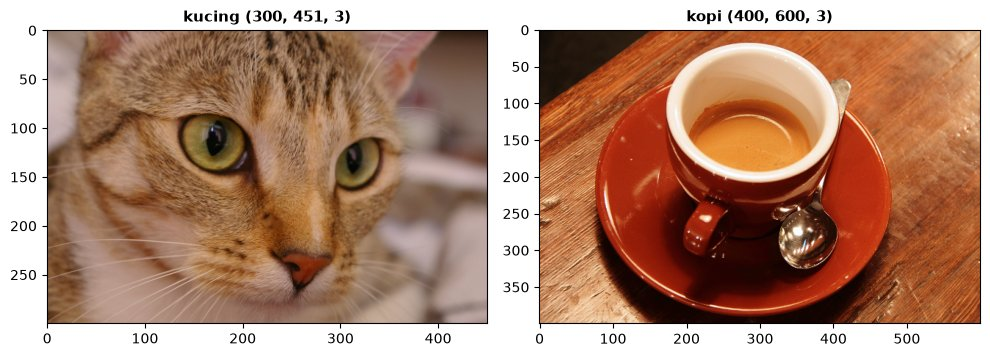

In [2]:
# Pencarian berkas citra defensif (notebook bisa dijalankan dari root repo atau folder notebook_handson)
def find_image(filename):
    possible_paths = [
        f"image/{filename}",
        f"notebook_handson/image/{filename}",
        f"../image/{filename}",
    ]
    return next((p for p in possible_paths if os.path.exists(p)), None)


def baca(filename, flag=cv2.IMREAD_COLOR):
    # cv2.imread TIDAK melempar error bila path salah -> kita periksa sendiri
    path = find_image(filename)
    img = cv2.imread(path, flag) if path else None
    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan / gagal dibaca: {filename}")
    return img


def tampil(ax, img, judul=None, sumbu=False):
    # Menampilkan citra OpenCV (BGR / grayscale) di matplotlib; sumbu=True menampilkan koordinat piksel
    if img.ndim == 2:
        ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    else:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    if not sumbu:
        ax.set_xticks([]); ax.set_yticks([])
    if judul:
        ax.set_title(judul, fontsize=11, fontweight='bold')


def jajar(daftar, ukuran=4, sumbu=False):
    # Menampilkan beberapa citra berdampingan: daftar = [(img, judul), ...]
    fig, axes = plt.subplots(1, len(daftar), figsize=(ukuran * len(daftar), ukuran * 0.8))
    for ax, (im, judul) in zip(np.atleast_1d(axes), daftar):
        tampil(ax, im, judul, sumbu)
    plt.tight_layout(); plt.show()


kucing = baca("chelsea.png")
kopi = baca("coffee.png")
h, w = kucing.shape[:2]

print("kucing:", kucing.shape, "| kopi:", kopi.shape)
jajar([(kucing, f"kucing {kucing.shape}"), (kopi, f"kopi {kopi.shape}")], ukuran=5, sumbu=True)

### 🧪 Pemeriksa Jawaban Challenge
Sel berikut berisi fungsi pemeriksa untuk setiap 🧩 Challenge. **Cukup jalankan sekali**, tidak perlu dibaca. (Kalau penasaran boleh, tetapi cobalah menjawab sendiri dulu 😉)

In [3]:
def _belum(*nilai):
    if any(v is None for v in nilai):
        print("⏳ Masih ada TODO yang bernilai None. Isi dulu, lalu jalankan sel ini lagi.")
        return True
    return False


def _lapor(benar, pesan_benar, pesan_salah):
    print(("✅ Benar! " + pesan_benar) if benar else ("❌ Belum tepat. " + pesan_salah))
    return benar


def cek_c1(img, cx, cy):
    if _belum(cx, cy): return
    h_, w_ = img.shape[:2]
    if abs(cx - h_ / 2) <= 1 and abs(cy - w_ / 2) <= 1:
        return _lapor(False, "", "cx dan cy tertukar: x berasal dari LEBAR (w), y dari TINGGI (h).")
    if _lapor(abs(cx - w_ / 2) <= 1 and abs(cy - h_ / 2) <= 1, f"Pusat citra = ({cx}, {cy}).",
              "Pusat x ada di tengah LEBAR, pusat y ada di tengah TINGGI."):
        demo = img.copy()
        cv2.drawMarker(demo, (int(cx), int(cy)), (0, 255, 255), cv2.MARKER_CROSS, 40, 3)
        jajar([(demo, f"pusat ({cx}, {cy})")], ukuran=5)


def cek_c2(img, selfie):
    if _belum(selfie): return
    if np.array_equal(selfie, img[::-1]):
        return _lapor(False, "", "Itu flip ATAS-BAWAH. Kamera selfie membalik KIRI-KANAN.")
    if _lapor(np.array_equal(selfie, img[:, ::-1]), "Kiri dan kanan tertukar seperti cermin.",
              "Hasilnya belum sama dengan cermin kiri-kanan. Coba flipCode 1, atau balik urutan kolom."):
        jajar([(img, "Asli"), (selfie, "Selfie")], ukuran=4)


def cek_c3(atas, bawah, hasil):
    if _belum(atas, bawah, hasil): return
    ok_a, ok_b, ok_h = np.isclose(atas, 150), np.isclose(bawah, 100), np.isclose(hasil, 137.5)
    print(f"atas  = {atas}  " + ("✅" if ok_a else "❌ (interpolasi 100 → 200 pada x = 0.5)"))
    print(f"bawah = {bawah}  " + ("✅" if ok_b else "❌ (interpolasi 50 → 150 pada x = 0.5)"))
    print(f"hasil = {hasil}  " + ("✅" if ok_h else "❌ (interpolasi atas → bawah pada y = 0.25)"))
    if ok_a and ok_b and ok_h:
        print("✅ Benar! Inilah yang dihitung cv2.INTER_LINEAR untuk setiap piksel baru.")


def cek_c4(img, thumb):
    if _belum(thumb): return
    h_, w_ = img.shape[:2]
    hb = round(h_ * 200 / w_)
    if thumb.shape[:2] == (200, hb):
        return _lapor(False, "", f"Ukuran tertukar: shape {thumb.shape[:2]}. Ingat dsize = (W, H).")
    if thumb.shape[:2] != (hb, 200):
        return _lapor(False, "", f"shape {thumb.shape[:2]} belum sesuai. Tinggi baru = h × lebar_baru / w.")
    if not np.array_equal(thumb, cv2.resize(img, (200, hb), interpolation=cv2.INTER_AREA)):
        return _lapor(False, "", "Ukuran sudah benar, tetapi untuk MENGECILKAN gunakan interpolation=cv2.INTER_AREA.")
    _lapor(True, f"thumb.shape = {thumb.shape}, rasio aspek terjaga.", "")
    jajar([(thumb, f"thumbnail {thumb.shape[:2]}")], ukuran=3, sumbu=True)


def cek_c5(img, M, hasil):
    if _belum(M, hasil): return
    h_, w_ = img.shape[:2]
    M = np.asarray(M, np.float64)
    ref = cv2.getRotationMatrix2D((w_ / 2, h_ / 2), -30, 1.0)
    kebalik = cv2.getRotationMatrix2D((w_ / 2, h_ / 2), 30, 1.0)
    if M.shape != (2, 3):
        return _lapor(False, "", "M harus berukuran 2x3 (hasil cv2.getRotationMatrix2D).")
    if np.allclose(M[:, :2], kebalik[:, :2], atol=1e-3):
        return _lapor(False, "", "Arahnya terbalik: angle POSITIF = BERLAWANAN jarum jam.")
    if not np.allclose(M[:, :2], ref[:, :2], atol=1e-3):
        return _lapor(False, "", "Sudut atau skala belum tepat (skala = 1.0).")
    if np.abs(M[:, 2] - ref[:, 2]).max() > 2:
        return _lapor(False, "", "Pusat putar belum di tengah. Urutannya (x, y) = (w/2, h/2).")
    if hasil.shape != img.shape:
        return _lapor(False, "", f"Ukuran keluaran {hasil.shape[:2]} berbeda dari asli. dsize = (w, h).")
    _lapor(True, "Kucing berputar 30° searah jarum jam di pusatnya.", "")
    jajar([(img, "Asli"), (hasil, "-30°")], ukuran=4.5)


def cek_c6(img, M):
    if _belum(M): return
    M = np.asarray(M, np.float64)
    if M.shape != (2, 3):
        return _lapor(False, "", "M harus 2 baris x 3 kolom.")
    if np.allclose(M, [[1, 0, 40], [0, 1, 25]]):
        return _lapor(False, "", "ty = +25 menggeser ke BAWAH (sumbu y menghadap ke bawah). Ke atas = ty negatif.")
    if np.allclose(M, [[1, 0, -40], [0, 1, -25]]):
        return _lapor(False, "", "tx = -40 menggeser ke KIRI.")
    if _lapor(np.allclose(M, [[1, 0, 40], [0, 1, -25]]), "Translasi 40 px ke kanan, 25 px ke atas.",
              "Bagian 2x2 kiri harus identitas [[1, 0], [0, 1]]; kolom ketiga = (tx, ty)."):
        h_, w_ = img.shape[:2]
        jajar([(img, "Asli"), (cv2.warpAffine(img, np.float32(M), (w_, h_)), "warpAffine(kucing, M, (w, h))")], ukuran=4.5)


def cek_c7(img, sudut, W_baru, H_baru):
    if _belum(W_baru, H_baru): return
    h_, w_ = img.shape[:2]
    c, s = abs(np.cos(np.deg2rad(sudut))), abs(np.sin(np.deg2rad(sudut)))
    W_ref, H_ref = round(w_ * c + h_ * s), round(w_ * s + h_ * c)
    if abs(W_baru - H_ref) <= 1 and abs(H_baru - W_ref) <= 1:
        return _lapor(False, "", "W' dan H' tertukar. W' = w·|cos θ| + h·|sin θ|.")
    if _lapor(abs(W_baru - W_ref) <= 1 and abs(H_baru - H_ref) <= 1, f"Kanvas baru = {W_baru} × {H_baru} (W × H).",
              "Rumus: W' = w·|cos θ| + h·|sin θ|, H' = w·|sin θ| + h·|cos θ|. "
              "np.cos memakai RADIAN: np.cos(np.deg2rad(60))."):
        if 'rotate_bound' in globals():
            r = rotate_bound(img, sudut)
            print(f"Bukti: rotate_bound(kopi, {sudut}).shape = {r.shape}")
            jajar([(r, f"{sudut}° tanpa terpotong")], ukuran=5)


def cek_c8(box, pt1, pt2, hasil):
    if _belum(pt1, pt2): return
    x, y, bw, bh = box
    if tuple(pt2) == (bw, bh):
        return _lapor(False, "", "pt2 adalah KOORDINAT sudut kanan-bawah, bukan ukuran kotak.")
    if _lapor(tuple(pt1) == (x, y) and tuple(pt2) == (x + bw, y + bh), f"pt1 = {tuple(pt1)}, pt2 = {tuple(pt2)}.",
              "pt1 = sudut kiri-atas (x, y); pt2 = sudut kanan-bawah."):
        jajar([(hasil, "Hidung kucing")], ukuran=5)


def cek_c9(img, box, x_baru):
    if _belum(x_baru): return
    x, y, bw, bh = box
    w_ = img.shape[1]
    if x_baru in (w_ - x, w_ - 1 - x):
        return _lapor(False, "", "Hampir! Itu posisi tepi KANAN kotak setelah dibalik. Kurangi lagi dengan lebar kotak.")
    if _lapor(x_baru == w_ - x - bw, f"x baru = {x_baru}.",
              "Petunjuk: tepi KANAN kotak (x + bw) setelah dibalik menjadi tepi KIRI yang baru."):
        demo = cv2.flip(img, 1)
        cv2.rectangle(demo, (int(x_baru), y), (int(x_baru) + bw, y + bh), (0, 255, 255), 3)
        jajar([(demo, f"flip + kotak di x = {x_baru}")], ukuran=5)


print("Pemeriksa challenge siap: cek_c1 ... cek_c9")

Pemeriksa challenge siap: cek_c1 ... cek_c9


## 2. Alamat Piksel: Fondasi Semua Transformasi

Setiap piksel punya **alamat** `(x, y)`: `x` = kolom (ke kanan), `y` = baris (**ke bawah**). Titik asal `(0, 0)` ada di **kiri-atas**.

**Transformasi geometris = aturan untuk menghitung alamat baru** `(x, y) → (x', y')`. Nilai piksel tidak diubah, hanya dipindah.

| Konteks | Urutan | Contoh |
|---|---|---|
| Indeks NumPy | `[y, x]` (baris dulu) | `img[136, 318]` |
| `img.shape` | `(H, W, C)` | `(300, 451, 3)` |
| Titik OpenCV | `(x, y)` | `cv2.circle(img, (318, 136), ...)` |
| Ukuran OpenCV (`dsize`) | `(W, H)` | `cv2.resize(img, (451, 300))` |

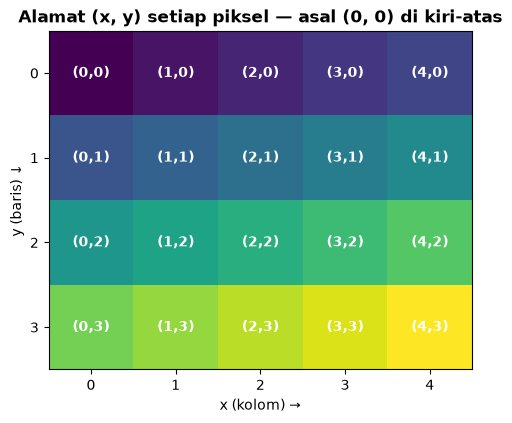

mini.shape = (4, 5) -> 4 baris (h) x 5 kolom (w)
Piksel di x=3, y=1 dibaca dengan mini[1, 3] = 96


In [4]:
mini = (np.arange(20).reshape(4, 5) * 12).astype(np.uint8)

fig, ax = plt.subplots(figsize=(6, 4.4))
ax.imshow(mini, cmap='viridis')
for yy in range(4):
    for xx in range(5):
        ax.text(xx, yy, f"({xx},{yy})", ha='center', va='center', color='w', fontsize=10, fontweight='bold')
ax.set_xticks(range(5)); ax.set_yticks(range(4))
ax.set_xlabel("x (kolom) →"); ax.set_ylabel("y (baris) ↓")
ax.set_title("Alamat (x, y) setiap piksel — asal (0, 0) di kiri-atas", fontweight='bold')
plt.show()

print("mini.shape =", mini.shape, "-> 4 baris (h) x 5 kolom (w)")
print("Piksel di x=3, y=1 dibaca dengan mini[1, 3] =", mini[1, 3])

Nilai BGR kucing[y, x] = [19 23 24]
kucing[x, y] -> IndexError: index 318 is out of bounds for axis 0 with size 300


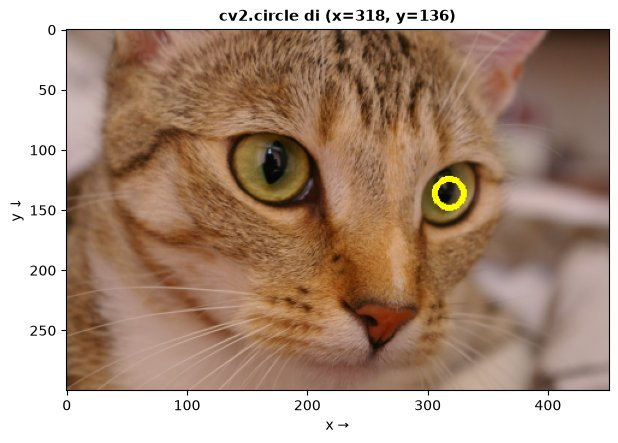

In [5]:
x, y = 318, 136                                    # sebuah titik di mata kanan kucing
demo = kucing.copy()
cv2.circle(demo, (x, y), 12, (0, 255, 255), 3)    # OpenCV: (x, y)
print("Nilai BGR kucing[y, x] =", kucing[y, x])     # NumPy: [y, x]

try:
    kucing[x, y]                                    # urutan terbalik!
except IndexError as err:
    print("kucing[x, y] -> IndexError:", err)

fig, ax = plt.subplots(figsize=(7, 4.8))
tampil(ax, demo, "cv2.circle di (x=318, y=136)", sumbu=True)
ax.set_xlabel("x →"); ax.set_ylabel("y ↓")
plt.show()

### 🧩 Challenge 1 — Tandai Pusat Citra *(2 menit)*
Hitung koordinat **pusat** citra kucing `(cx, cy)` dari `h` dan `w`. Pemeriksa akan menggambar tanda silang di titik itu.

In [6]:
# 🧩 CHALLENGE 1 — ganti None dengan rumus (gunakan h dan w)
h, w = kucing.shape[:2]

cx = None   # TODO: koordinat x pusat citra
cy = None   # TODO: koordinat y pusat citra

cek_c1(kucing, cx, cy)

⏳ Masih ada TODO yang bernilai None. Isi dulu, lalu jalankan sel ini lagi.


⏸️ **Kembali ke slide** — pembahasan Challenge 1, lalu translasi & flipping.

---
## 3. Translasi: Menggeser Semua Piksel

$$x' = x + t_x \qquad y' = y + t_y$$

$t_x > 0$ menggeser ke **kanan**, $t_y > 0$ menggeser ke **bawah**. Untuk pergeseran bilangan bulat cukup memakai slicing NumPy: buat kanvas hitam, lalu tempel bagian citra yang masih muat.

Piksel asal  kucing[136, 318] = [19 23 24]
Sekarang di  hasil[176, 398]  = [19 23 24]  (y + 40, x + 80)
Kolom kiri hasil (x < 80) semuanya hitam? True


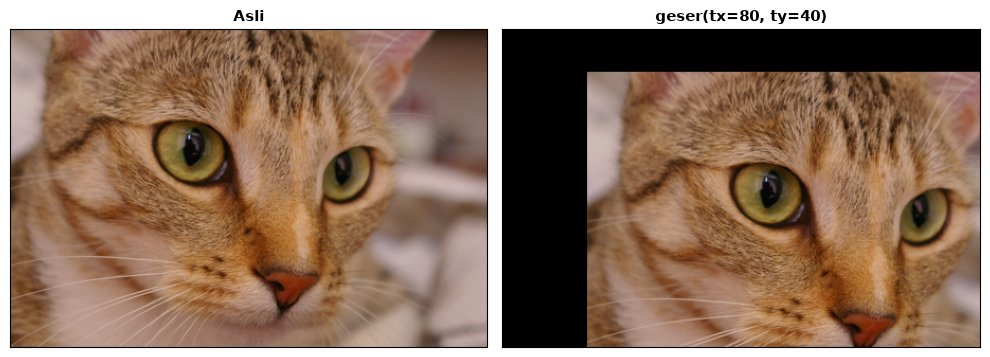

In [7]:
def geser(img, tx, ty):
    # Translasi dengan slicing NumPy (tx, ty >= 0): geser ke kanan tx, ke bawah ty
    h_, w_ = img.shape[:2]
    out = np.zeros_like(img)                   # kanvas hitam berukuran sama
    out[ty:, tx:] = img[:h_ - ty, :w_ - tx]    # tempel bagian yang masih muat
    return out


hasil = geser(kucing, 80, 40)
print("Piksel asal  kucing[136, 318] =", kucing[136, 318])
print("Sekarang di  hasil[176, 398]  =", hasil[136 + 40, 318 + 80], " (y + 40, x + 80)")
print("Kolom kiri hasil (x < 80) semuanya hitam?", (hasil[:, :80] == 0).all())
jajar([(kucing, "Asli"), (hasil, "geser(tx=80, ty=40)")], ukuran=5)

Perhatikan dua efek di tepi: **area kosong** (diisi 0 = hitam) dan **bagian yang keluar kanvas hilang**. Kanvas tidak ikut membesar.

## 4. Flipping: Cermin

| Arah | Aturan alamat | NumPy | OpenCV |
|---|---|---|---|
| Horizontal (kiri-kanan) | $x' = (w-1) - x$ | `img[:, ::-1]` | `cv2.flip(img, 1)` |
| Vertikal (atas-bawah) | $y' = (h-1) - y$ | `img[::-1, :]` | `cv2.flip(img, 0)` |
| Keduanya | keduanya | `img[::-1, ::-1]` | `cv2.flip(img, -1)` |

kucing[:, ::-1]    == cv2.flip(kucing, 1) ? True
kucing[::-1, :]    == cv2.flip(kucing, 0) ? True
kucing[::-1, ::-1] == cv2.flip(kucing, -1)? True
flip -1 == rotasi 180°? True

Mata kanan (x=318) setelah flip horizontal pindah ke x' = (w-1) - x = 132
Nilainya sama? True


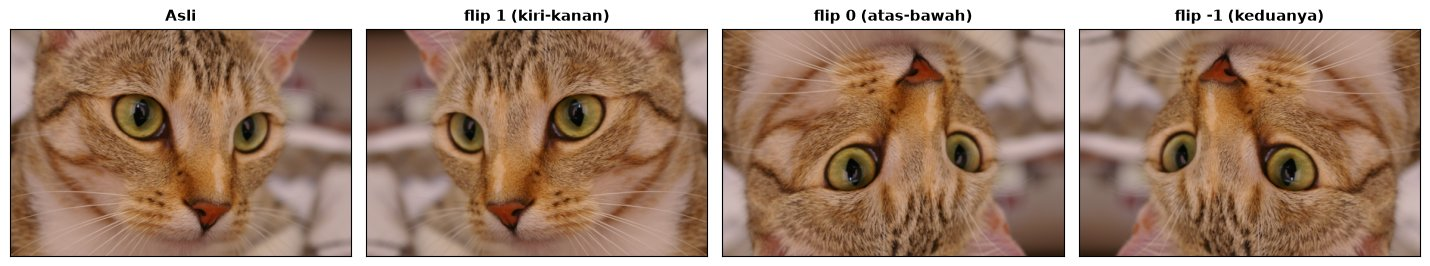

In [8]:
flip_h = kucing[:, ::-1]        # balik urutan kolom
flip_v = kucing[::-1, :]        # balik urutan baris
flip_hv = kucing[::-1, ::-1]    # keduanya

print("kucing[:, ::-1]    == cv2.flip(kucing, 1) ?", np.array_equal(flip_h, cv2.flip(kucing, 1)))
print("kucing[::-1, :]    == cv2.flip(kucing, 0) ?", np.array_equal(flip_v, cv2.flip(kucing, 0)))
print("kucing[::-1, ::-1] == cv2.flip(kucing, -1)?", np.array_equal(flip_hv, cv2.flip(kucing, -1)))
print("flip -1 == rotasi 180°?", np.array_equal(flip_hv, cv2.rotate(kucing, cv2.ROTATE_180)))

x, y = 318, 136
print(f"\nMata kanan (x={x}) setelah flip horizontal pindah ke x' = (w-1) - x = {w - 1 - x}")
print("Nilainya sama?", np.array_equal(kucing[y, x], flip_h[y, w - 1 - x]))

jajar([(kucing, "Asli"), (flip_h, "flip 1 (kiri-kanan)"), (flip_v, "flip 0 (atas-bawah)"), (flip_hv, "flip -1 (keduanya)")], ukuran=3.6)

### 🧩 Challenge 2 — Efek Kamera Selfie *(2 menit)*
Kamera depan HP menampilkan bayangan **cermin**. Buat `selfie` dari `kucing` dalam **satu baris**, boleh dengan NumPy atau OpenCV.

In [9]:
# 🧩 CHALLENGE 2 — cermin kiri-kanan
selfie = None   # TODO: satu baris

cek_c2(kucing, selfie)

⏳ Masih ada TODO yang bernilai None. Isi dulu, lalu jalankan sel ini lagi.


⏸️ **Kembali ke slide** — pembahasan Challenge 2, lalu scaling & interpolasi.

---
## 5. Scaling & Interpolasi

### 5.1 `cv2.resize`: dua cara menyebut ukuran

In [10]:
besar = cv2.resize(kucing, (902, 600))              # dsize = (W, H)
kecil = cv2.resize(kucing, None, fx=0.5, fy=0.5)    # atau pakai faktor skala

print("asli :", kucing.shape)
print("besar:", besar.shape, " <- dsize=(902, 600) berarti W=902, H=600")
print("kecil:", kecil.shape, " <- fx=fy=0.5")

asli : (300, 451, 3)
besar: (600, 902, 3)  <- dsize=(902, 600) berarti W=902, H=600
kecil: (150, 226, 3)  <- fx=fy=0.5


### 5.2 Masalah "Lubang": Mendorong vs Menarik
Memperbesar 2× dengan **mendorong** setiap piksel ke alamat baru ($x' = 2x$) meninggalkan banyak **lubang**. Solusinya **berpikir terbalik**: untuk setiap piksel tujuan, tanyakan *"aku berasal dari alamat mana?"* ($x = x'/2$). Cara ini disebut **inverse mapping**, dan dipakai oleh semua fungsi geometri OpenCV.

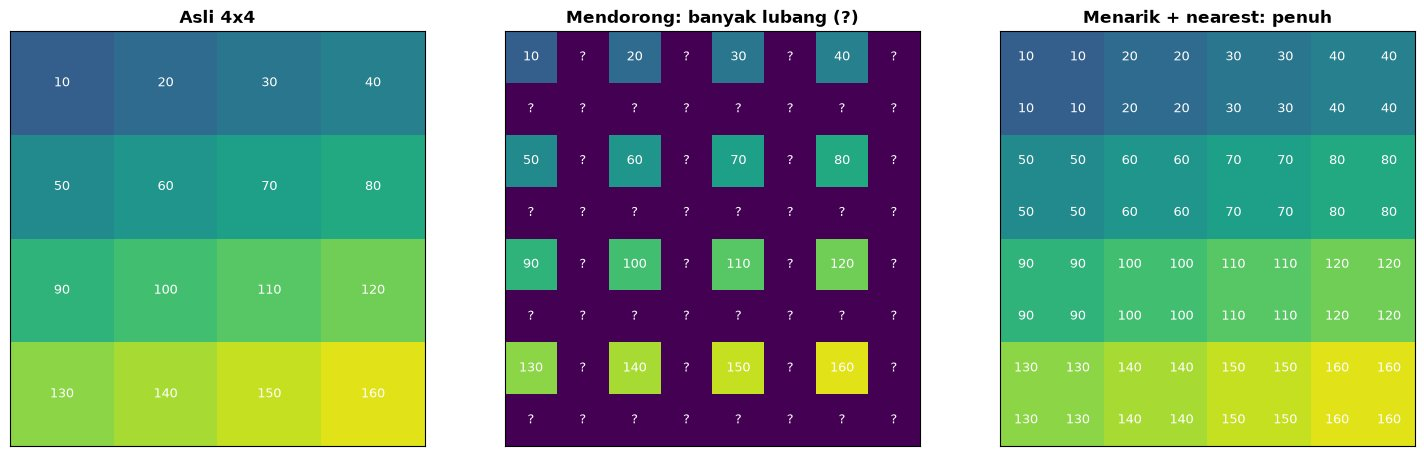

Jumlah lubang saat mendorong: 48 dari 64 piksel


In [11]:
src = np.arange(10, 170, 10, dtype=np.float32).reshape(4, 4)
s = 2

maju = np.full((8, 8), np.nan, dtype=np.float32)
for yy in range(4):
    for xx in range(4):
        maju[yy * s, xx * s] = src[yy, xx]                  # DORONG: x' = 2x

mundur = np.zeros((8, 8), dtype=np.float32)
for yb in range(8):
    for xb in range(8):
        mundur[yb, xb] = src[int(yb / s), int(xb / s)]     # TARIK: x = x' / 2 (dibulatkan ke bawah)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, arr, judul in [(axes[0], src, "Asli 4x4"), (axes[1], maju, "Mendorong: banyak lubang (?)"),
                       (axes[2], mundur, "Menarik + nearest: penuh")]:
    ax.imshow(np.nan_to_num(arr, nan=-60), cmap='viridis', vmin=-60, vmax=170)
    for (yy, xx), v in np.ndenumerate(arr):
        ax.text(xx, yy, "?" if np.isnan(v) else int(v), ha='center', va='center', color='w', fontsize=9)
    ax.set_title(judul, fontweight='bold'); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()
print("Jumlah lubang saat mendorong:", int(np.isnan(maju).sum()), "dari", maju.size, "piksel")

### 5.3 Nearest Neighbor = Mengulang Piksel
Saat menarik, alamat asal sering **pecahan** (misal $x = 1.5$). *Nearest* hanya mengambil piksel terdekat, sehingga untuk skala 2× hasilnya sama dengan mengulang setiap piksel 2×2 kali.

In [12]:
k4 = np.array([[10, 20],
               [30, 40]], dtype=np.uint8)
nn = cv2.resize(k4, (4, 4), interpolation=cv2.INTER_NEAREST)
rep = np.repeat(np.repeat(k4, 2, axis=0), 2, axis=1)

print("cv2.resize INTER_NEAREST:\n", nn)
print("np.repeat:\n", rep)
print("Sama?", np.array_equal(nn, rep))

cv2.resize INTER_NEAREST:
 [[10 10 20 20]
 [10 10 20 20]
 [30 30 40 40]
 [30 30 40 40]]
np.repeat:
 [[10 10 20 20]
 [10 10 20 20]
 [30 30 40 40]
 [30 30 40 40]]
Sama? True


### 5.4 Bilinear = Rata-rata Berbobot dari 4 Tetangga
Untuk titik pecahan $(x, y)$ di dalam petak 2×2, bilinear bekerja dalam **tiga langkah**:
1. Interpolasi **baris atas** pada posisi $x$.
2. Interpolasi **baris bawah** pada posisi $x$.
3. Interpolasi **vertikal** antara keduanya pada posisi $y$.

Rumus 1D yang dipakai berulang: $\; a + t\,(b - a)$, dengan $t$ = jarak dari $a$ (antara 0 dan 1).

In [13]:
def bilinear(patch, x, y):
    # Interpolasi bilinear pada petak 2x2; x dan y bernilai antara 0 dan 1
    kiri_atas, kanan_atas = patch[0, 0], patch[0, 1]
    kiri_bawah, kanan_bawah = patch[1, 0], patch[1, 1]
    atas = kiri_atas + x * (kanan_atas - kiri_atas)          # langkah 1
    bawah = kiri_bawah + x * (kanan_bawah - kiri_bawah)      # langkah 2
    return atas + y * (bawah - atas)                         # langkah 3


p = np.array([[10, 20],
              [30, 40]], dtype=np.float32)
for (x, y) in [(0, 0), (0.5, 0), (0.5, 0.5), (0.25, 0.5), (1, 1)]:
    # pembanding: cv2.remap mengambil nilai citra pada koordinat pecahan dengan INTER_LINEAR
    ref = cv2.remap(p, np.float32([[x]]), np.float32([[y]]), cv2.INTER_LINEAR,
                    borderMode=cv2.BORDER_REPLICATE)[0, 0]
    print(f"(x={x:<4}, y={y:<4}) -> manual {bilinear(p, x, y):6.2f} | OpenCV {ref:6.2f}")

(x=0   , y=0   ) -> manual  10.00 | OpenCV  10.00
(x=0.5 , y=0   ) -> manual  15.00 | OpenCV  15.00
(x=0.5 , y=0.5 ) -> manual  25.00 | OpenCV  25.00
(x=0.25, y=0.5 ) -> manual  22.50 | OpenCV  22.50
(x=1   , y=1   ) -> manual  40.00 | OpenCV  40.00


### 🧩 Challenge 3 — Hitung Bilinear Sendiri *(4 menit)*
Hitung **dulu di kertas**, lalu tuliskan angkanya (atau rumusnya) di sel berikut. Titik yang dicari: $(x = 0.5,\ y = 0.25)$.

```
        x=0    x=1
y=0  [ 100,   200 ]
y=1  [  50,   150 ]
```

In [14]:
# 🧩 CHALLENGE 3 — bilinear di titik (x=0.5, y=0.25)
atas = None    # TODO: nilai di baris atas pada x = 0.5
bawah = None   # TODO: nilai di baris bawah pada x = 0.5
hasil = None   # TODO: gabungkan atas & bawah pada y = 0.25

cek_c3(atas, bawah, hasil)

⏳ Masih ada TODO yang bernilai None. Isi dulu, lalu jalankan sel ini lagi.


⏸️ **Kembali ke slide** — pembahasan Challenge 3.

### 5.5 Memperbesar 12×: Empat Metode

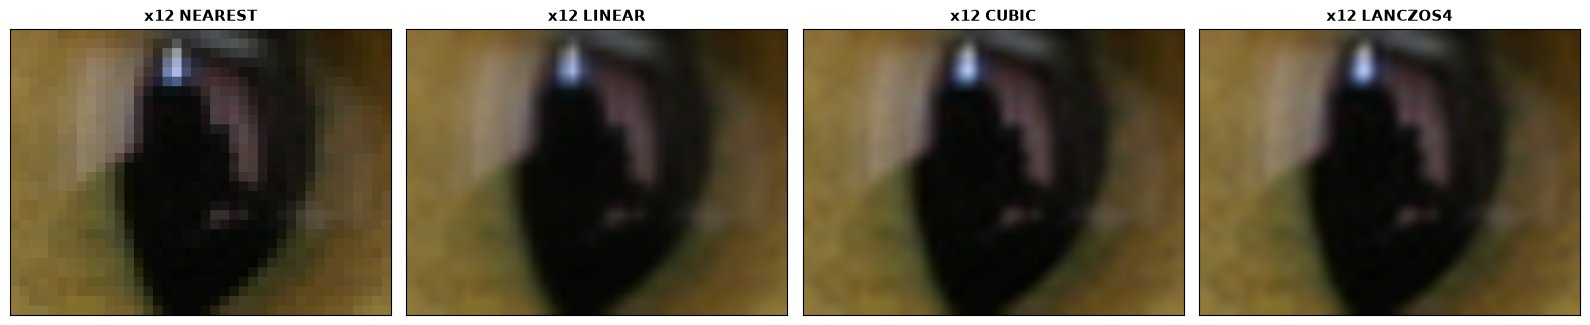

In [15]:
pupil = kucing[98:128, 152:192]        # potongan kecil 30x40 di pupil mata kiri
metode = {"NEAREST": cv2.INTER_NEAREST, "LINEAR": cv2.INTER_LINEAR,
          "CUBIC": cv2.INTER_CUBIC, "LANCZOS4": cv2.INTER_LANCZOS4}
jajar([(cv2.resize(pupil, None, fx=12, fy=12, interpolation=f), f"x12 {n}") for n, f in metode.items()], ukuran=4)

### 5.6 Mengecilkan: Bahaya Aliasing (Ingat Pertemuan 3!)
Mengecilkan citra = **resampling 2D**. Seperti downsampling audio tanpa filter anti-aliasing, detail yang terlalu rapat berubah menjadi **pola palsu** (*moiré*). `INTER_AREA` merata-ratakan piksel di setiap area (berfungsi sebagai *low-pass filter*), sehingga detail yang tidak muat menjadi abu-abu, bukan pola palsu.

Kita uji dengan *zone plate*: cincin yang makin rapat ke arah tepi.

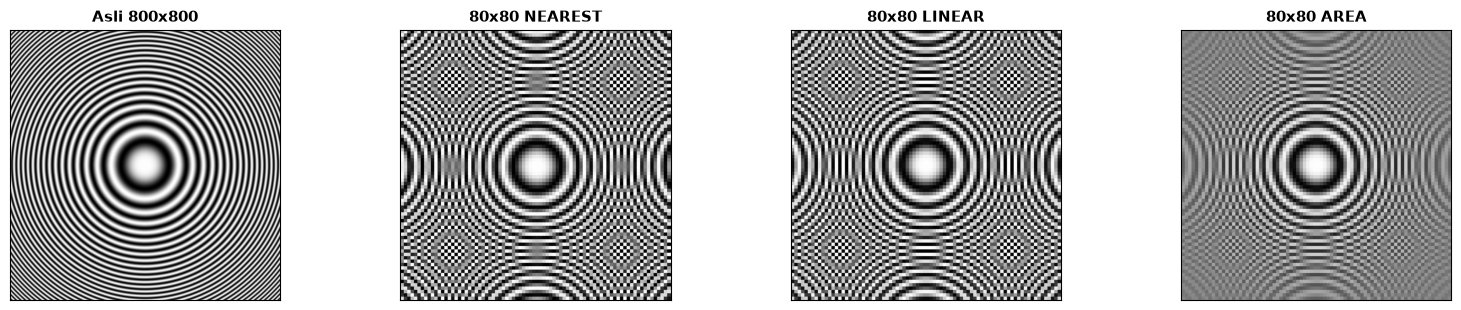

In [16]:
n = 800
yy, xx = np.mgrid[-1:1:n * 1j, -1:1:n * 1j]
zone = ((np.cos(100 * (xx ** 2 + yy ** 2)) + 1) * 127.5).astype(np.uint8)

hasil_kecil = {nama: cv2.resize(zone, (80, 80), interpolation=f)
               for nama, f in [("NEAREST", cv2.INTER_NEAREST), ("LINEAR", cv2.INTER_LINEAR), ("AREA", cv2.INTER_AREA)]}

# hasil 80x80 diperbesar kembali (nearest) hanya agar mudah dilihat
jajar([(zone, "Asli 800x800")] +
      [(cv2.resize(v, (800, 800), interpolation=cv2.INTER_NEAREST), f"80x80 {k}") for k, v in hasil_kecil.items()], ukuran=4)

### 5.7 Mask Segmentasi Wajib `INTER_NEAREST`
Mask hanya boleh berisi label (misal 0 dan 255). Interpolasi linear menciptakan **nilai baru** di tepi yang bukan label mana pun.

Nilai unik mask asli : [  0 255]
Nilai unik LINEAR    : 46 nilai berbeda  <- muncul 'label' baru!
Nilai unik NEAREST   : [  0 255]


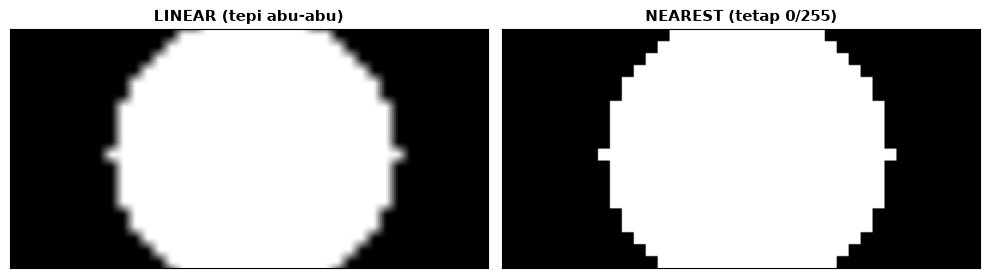

In [17]:
mask = np.zeros((40, 60), np.uint8)
cv2.circle(mask, (30, 20), 12, 255, -1)          # mask biner: hanya 0 atau 255

m_lin = cv2.resize(mask, None, fx=6, fy=6, interpolation=cv2.INTER_LINEAR)
m_nn = cv2.resize(mask, None, fx=6, fy=6, interpolation=cv2.INTER_NEAREST)
print("Nilai unik mask asli :", np.unique(mask))
print("Nilai unik LINEAR    :", len(np.unique(m_lin)), "nilai berbeda  <- muncul 'label' baru!")
print("Nilai unik NEAREST   :", np.unique(m_nn))
jajar([(m_lin[60:180, 60:300], "LINEAR (tepi abu-abu)"), (m_nn[60:180, 60:300], "NEAREST (tetap 0/255)")], ukuran=5)

### 5.8 Rasio Aspek
Memaksa ukuran tujuan tanpa memperhatikan rasio $W:H$ membuat citra **gepeng**.

Rasio asli  W/H = 1.503
Rasio paksa W/H = 1.0


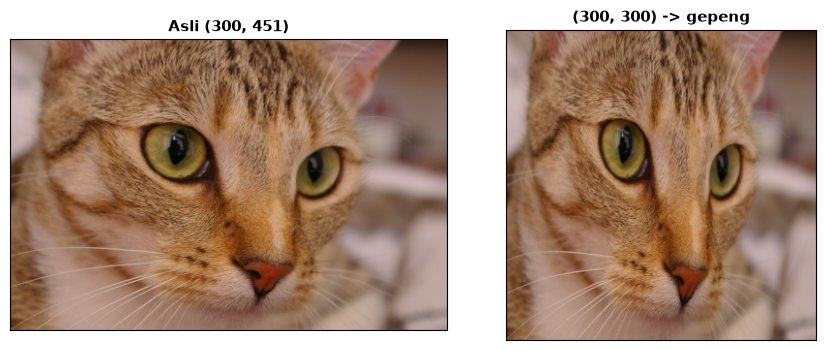

In [18]:
gepeng = cv2.resize(kucing, (300, 300))
print("Rasio asli  W/H =", round(w / h, 3))
print("Rasio paksa W/H =", 300 / 300)
jajar([(kucing, f"Asli {kucing.shape[:2]}"), (gepeng, f"(300, 300) -> gepeng")], ukuran=4.5)

### 🧩 Challenge 4 — Thumbnail Lebar 200 Piksel *(3 menit)*
Buat thumbnail `kucing` dengan **lebar 200 px**, rasio aspek tetap, dan interpolasi yang tepat untuk **mengecilkan**.

In [19]:
# 🧩 CHALLENGE 4 — thumbnail lebar 200 px, rasio aspek tetap
h, w = kucing.shape[:2]
lebar_baru = 200

tinggi_baru = None   # TODO: hitung dari h, w, lebar_baru (bulatkan ke int)
thumb = None         # TODO: cv2.resize(kucing, (..., ...), interpolation=...)

cek_c4(kucing, thumb)

⏳ Masih ada TODO yang bernilai None. Isi dulu, lalu jalankan sel ini lagi.


⏸️ **Kembali ke slide** — pembahasan Challenge 4, lalu rotasi.

Versi fungsi yang bisa dipakai ulang:

In [20]:
def resize_lebar(img, lebar_baru, interp=cv2.INTER_AREA):
    # Ubah lebar citra dengan rasio aspek tetap
    h_, w_ = img.shape[:2]
    tinggi_baru = round(h_ * lebar_baru / w_)
    return cv2.resize(img, (lebar_baru, tinggi_baru), interpolation=interp)


for lb in [100, 200, 900]:
    interp = cv2.INTER_AREA if lb < w else cv2.INTER_CUBIC     # kecil -> AREA, besar -> CUBIC
    print(f"resize_lebar(kucing, {lb}) -> {resize_lebar(kucing, lb, interp).shape}")

resize_lebar(kucing, 100) -> (67, 100, 3)
resize_lebar(kucing, 200) -> (133, 200, 3)
resize_lebar(kucing, 900) -> (599, 900, 3)


---
## 6. Rotasi

### 6.1 Memutar Satu Titik
Rotasi titik $(x, y)$ sebesar $\theta$ terhadap titik asal $(0, 0)$:
$$x' = x\cos\theta - y\sin\theta \qquad y' = x\sin\theta + y\cos\theta$$
Karena sumbu $y$ citra menghadap **ke bawah**, rumus ini dengan $\theta$ positif terlihat **searah jarum jam** di layar.

In [21]:
def putar_titik(x, y, derajat):
    # Rotasi titik terhadap (0, 0) memakai rumus sin/cos (sudut dalam derajat)
    t = np.deg2rad(derajat)                  # np.cos / np.sin memakai RADIAN
    return x * np.cos(t) - y * np.sin(t), x * np.sin(t) + y * np.cos(t)


for d in [0, 30, 90, 180]:
    xb, yb = putar_titik(100, 0, d)
    print(f"(100, 0) diputar {d:3d}° -> ({xb:7.2f}, {yb:7.2f})")

(100, 0) diputar   0° -> ( 100.00,    0.00)
(100, 0) diputar  30° -> (  86.60,   50.00)
(100, 0) diputar  90° -> (   0.00,  100.00)
(100, 0) diputar 180° -> (-100.00,    0.00)


### 6.2 Di Mana Porosnya?
Jika poros di pojok `(0, 0)`, sebagian besar citra terlempar keluar kanvas. Memutar di **pusat** = 3 langkah: geser pusat ke `(0, 0)` → putar → geser balik. `cv2.getRotationMatrix2D(pusat, sudut, skala)` merangkum ketiganya menjadi satu matriks `M` (dibahas di §7), lalu `cv2.warpAffine` mengeksekusinya.

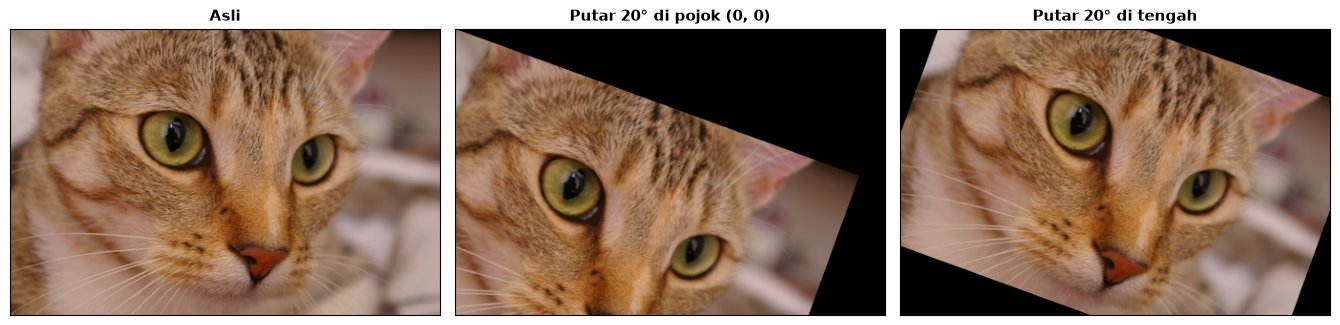

In [22]:
M_pojok = cv2.getRotationMatrix2D((0, 0), -20, 1.0)              # poros = pojok kiri-atas
M_tengah = cv2.getRotationMatrix2D((w / 2, h / 2), -20, 1.0)     # poros = pusat citra (x, y)!

jajar([(kucing, "Asli"),
       (cv2.warpAffine(kucing, M_pojok, (w, h)), "Putar 20° di pojok (0, 0)"),
       (cv2.warpAffine(kucing, M_tengah, (w, h)), "Putar 20° di tengah")], ukuran=4.5)

### 6.3 Arah Putaran di OpenCV
`cv2.getRotationMatrix2D`: **angle positif = berlawanan jarum jam**, negatif = searah jarum jam. Parameter ketiga adalah **skala** (1.0 = ukuran tetap).

M untuk +30°:
 [[  0.866   0.5   -44.789]
 [ -0.5     0.866 132.846]]


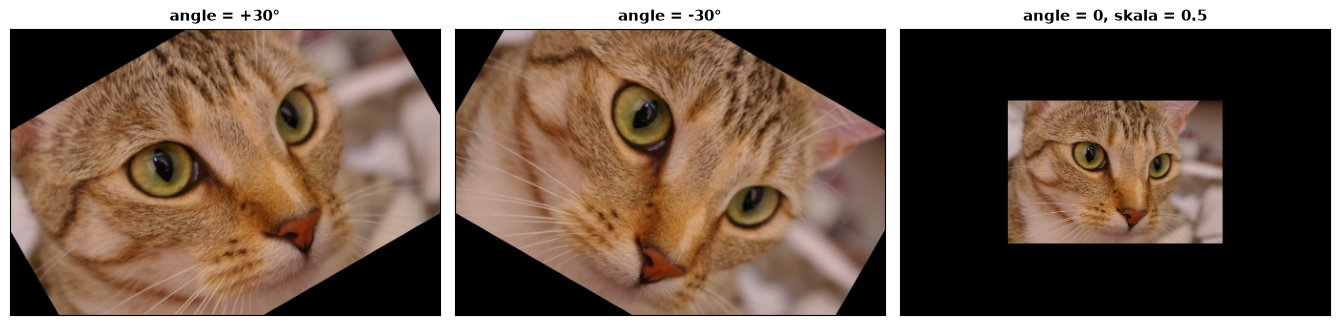

In [23]:
pusat = (w / 2, h / 2)
M = cv2.getRotationMatrix2D(pusat, 30, 1.0)
print("M untuk +30°:\n", np.round(M, 3))

jajar([(cv2.warpAffine(kucing, cv2.getRotationMatrix2D(pusat, a, 1.0), (w, h)), f"angle = {a:+d}°") for a in (30, -30)] +
      [(cv2.warpAffine(kucing, cv2.getRotationMatrix2D(pusat, 0, 0.5), (w, h)), "angle = 0, skala = 0.5")], ukuran=4.5)

### 🧩 Challenge 5 — Putar 30° Searah Jarum Jam *(3 menit)*
Putar `kucing` **30° searah jarum jam** di **pusat citra**, dengan ukuran keluaran sama seperti aslinya.

In [24]:
# 🧩 CHALLENGE 5 — rotasi 30° searah jarum jam di pusat citra
h, w = kucing.shape[:2]

M = None       # TODO: cv2.getRotationMatrix2D(pusat, sudut, skala)
hasil = None   # TODO: cv2.warpAffine(kucing, M, ukuran_keluaran)

cek_c5(kucing, M, hasil)

⏳ Masih ada TODO yang bernilai None. Isi dulu, lalu jalankan sel ini lagi.


⏸️ **Kembali ke slide** — pembahasan Challenge 5, lalu matriks affine.

---
## 7. Matriks Affine 2×3: Satu Bentuk untuk Semua

Semua transformasi di atas bisa ditulis dalam satu bentuk:
$$\begin{bmatrix} x' \\ y' \end{bmatrix} = \underbrace{\begin{bmatrix} a & b & t_x \\ c & d & t_y \end{bmatrix}}_{M} \begin{bmatrix} x \\ y \\ 1 \end{bmatrix}$$
Angka **1** tambahan membuat kolom ketiga $(t_x, t_y)$ ikut terjumlahkan, sehingga translasi juga bisa ditulis sebagai perkalian matriks.

### 7.1 Translasi sebagai Matriks

In [25]:
tx, ty = 80, 40
M_geser = np.float32([[1, 0, tx],
                      [0, 1, ty]])

titik = np.array([318, 136, 1])                    # (x, y, 1)
print("M_geser @ (318, 136, 1) =", M_geser @ titik, " -> (x + 80, y + 40)")

via_matriks = cv2.warpAffine(kucing, M_geser, (w, h))
print("warpAffine == geser() versi NumPy di §3 ?", np.array_equal(via_matriks, geser(kucing, tx, ty)))

M_geser @ (318, 136, 1) = [398. 176.]  -> (x + 80, y + 40)
warpAffine == geser() versi NumPy di §3 ? True


### 7.2 Keluarga Affine

Translasi:
[[ 1.  0. 60.]
 [ 0.  1. 30.]]

Scaling 0.6:
[[0.6 0.  0. ]
 [0.  0.6 0. ]]

Flip horizontal:
[[ -1.   0. 450.]
 [  0.   1.   0.]]

Rotasi 20°:
[[  0.94    0.342 -37.704]
 [ -0.342   0.94   86.172]]

Shear 0.4:
[[1.  0.4 0. ]
 [0.  1.  0. ]]

Flip via matriks == cv2.flip(kucing, 1)? True


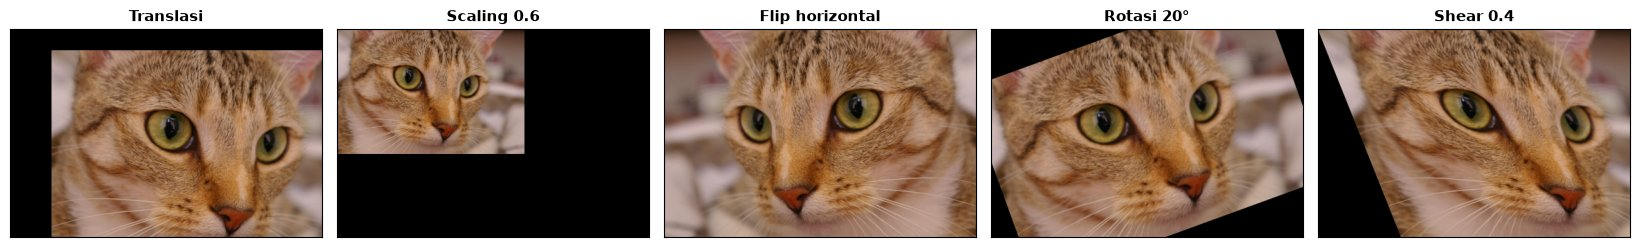

In [26]:
keluarga = {
    "Translasi": np.float32([[1, 0, 60], [0, 1, 30]]),
    "Scaling 0.6": np.float32([[0.6, 0, 0], [0, 0.6, 0]]),
    "Flip horizontal": np.float32([[-1, 0, w - 1], [0, 1, 0]]),
    "Rotasi 20°": cv2.getRotationMatrix2D((w / 2, h / 2), 20, 1.0),
    "Shear 0.4": np.float32([[1, 0.4, 0], [0, 1, 0]]),
}
for nama, M_ in keluarga.items():
    print(f"{nama}:\n{np.round(M_, 3)}\n")

print("Flip via matriks == cv2.flip(kucing, 1)?",
      np.array_equal(cv2.warpAffine(kucing, keluarga["Flip horizontal"], (w, h)), cv2.flip(kucing, 1)))
jajar([(cv2.warpAffine(kucing, M_, (w, h)), n) for n, M_ in keluarga.items()], ukuran=3.3)

### 7.3 Mengisi Area Kosong: `borderMode`

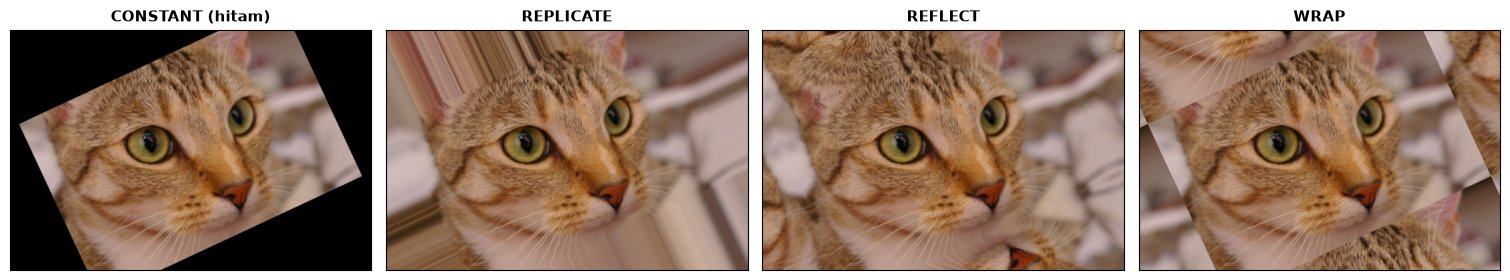

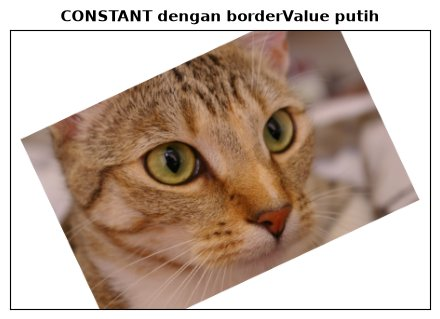

In [27]:
M_ = cv2.getRotationMatrix2D((w / 2, h / 2), 25, 0.8)
mode = {"CONSTANT (hitam)": cv2.BORDER_CONSTANT, "REPLICATE": cv2.BORDER_REPLICATE,
        "REFLECT": cv2.BORDER_REFLECT, "WRAP": cv2.BORDER_WRAP}
jajar([(cv2.warpAffine(kucing, M_, (w, h), borderMode=b), n) for n, b in mode.items()], ukuran=3.8)

putih = cv2.warpAffine(kucing, M_, (w, h), borderMode=cv2.BORDER_CONSTANT, borderValue=(255, 255, 255))
jajar([(putih, "CONSTANT dengan borderValue putih")], ukuran=4.5)

### 7.4 Affine dari 3 Pasang Titik
Matriks affine punya 6 angka, sehingga **3 pasang titik** (masing-masing memberi 2 persamaan) sudah cukup untuk menentukannya: `cv2.getAffineTransform`.

M dari 3 titik:
 [[ 7.58e-01 -1.00e-01  5.00e+01]
 [-4.40e-02  7.69e-01  3.00e+01]]


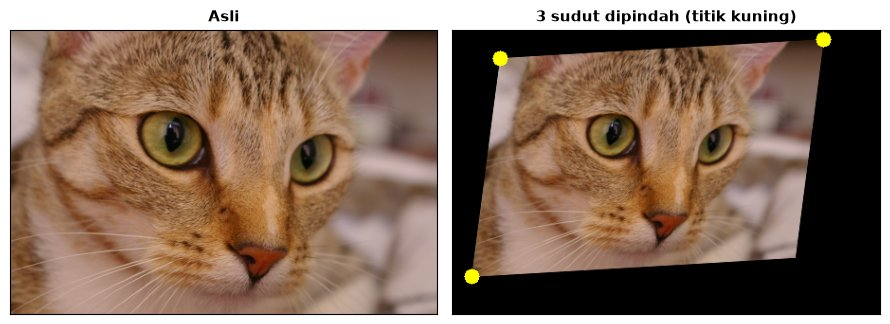

In [28]:
src3 = np.float32([[0, 0], [w - 1, 0], [0, h - 1]])               # kiri-atas, kanan-atas, kiri-bawah
dst3 = np.float32([[50, 30], [w - 60, 10], [20, h - 40]])        # posisi barunya
M3 = cv2.getAffineTransform(src3, dst3)
print("M dari 3 titik:\n", np.round(M3, 3))

hasil3 = cv2.warpAffine(kucing, M3, (w, h))
for (px, py) in dst3.astype(int):
    cv2.circle(hasil3, (px, py), 8, (0, 255, 255), -1)
jajar([(kucing, "Asli"), (hasil3, "3 sudut dipindah (titik kuning)")], ukuran=4.5)

### 🧩 Challenge 6 — Tulis Matriks Sendiri *(3 menit)*
Buat matriks `M` yang menggeser `kucing` **40 px ke kanan** dan **25 px ke atas**. Hati-hati dengan arah sumbu `y`!

In [29]:
# 🧩 CHALLENGE 6 — matriks translasi: 40 px ke KANAN, 25 px ke ATAS
M = None   # TODO: np.float32([[..., ..., ...], [..., ..., ...]])

cek_c6(kucing, M)

⏳ Masih ada TODO yang bernilai None. Isi dulu, lalu jalankan sel ini lagi.


⏸️ **Kembali ke slide** — pembahasan Challenge 6, lalu studi kasus rotasi tanpa terpotong.

---
## 8. Studi Kasus: Rotasi Tanpa Terpotong

### 8.1 Masalah: Kanvas Tetap → Sudut Terpotong

Piksel yang masih ada di kanvas: 77.9%  ->  hilang 22.1%


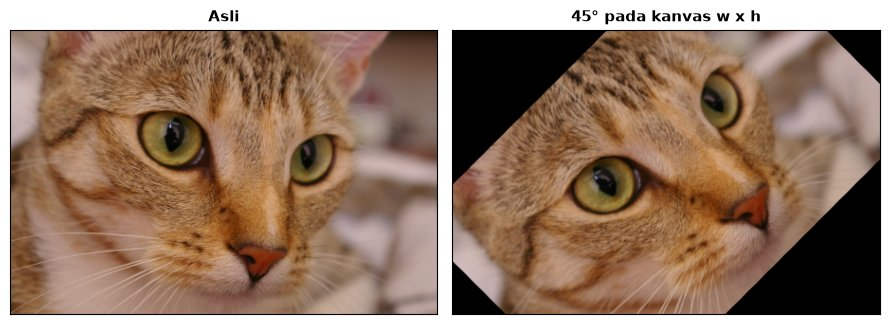

In [30]:
M45 = cv2.getRotationMatrix2D((w / 2, h / 2), 45, 1.0)
naif = cv2.warpAffine(kucing, M45, (w, h))

# Berapa persen piksel kucing yang hilang? Putar mask putih dengan cara yang sama lalu hitung yang masih di kanvas.
putih = np.full((h, w), 255, np.uint8)
masih_ada = (cv2.warpAffine(putih, M45, (w, h), flags=cv2.INTER_NEAREST) > 0).sum()
print(f"Piksel yang masih ada di kanvas: {masih_ada / (h * w):.1%}  ->  hilang {1 - masih_ada / (h * w):.1%}")
jajar([(kucing, "Asli"), (naif, "45° pada kanvas w x h")], ukuran=4.5)

### 8.2 Menghitung Kanvas Baru
Kotak pembungkus citra yang diputar:
$$W' = w\,|\cos\theta| + h\,|\sin\theta| \qquad H' = w\,|\sin\theta| + h\,|\cos\theta|$$
Nilai mutlak diperlukan karena untuk sudut tertentu (misal 120°) $\cos\theta$ bernilai negatif, padahal panjang tidak mungkin negatif.

In [31]:
sudut = 45
cos = abs(np.cos(np.deg2rad(sudut)))
sin = abs(np.sin(np.deg2rad(sudut)))
W_baru = round(w * cos + h * sin)
H_baru = round(w * sin + h * cos)

print(f"w = {w}, h = {h}, sudut = {sudut}°,  |cos| = {cos:.4f},  |sin| = {sin:.4f}")
print(f"W' = {w}·{cos:.4f} + {h}·{sin:.4f} = {w * cos + h * sin:.2f}  ->  {W_baru}")
print(f"H' = {w}·{sin:.4f} + {h}·{cos:.4f} = {w * sin + h * cos:.2f}  ->  {H_baru}")

w = 451, h = 300, sudut = 45°,  |cos| = 0.7071,  |sin| = 0.7071
W' = 451·0.7071 + 300·0.7071 = 531.04  ->  531
H' = 451·0.7071 + 300·0.7071 = 531.04  ->  531


### 8.3 `rotate_bound`: Empat Langkah
1. Buat matriks rotasi biasa di pusat lama.
2. Hitung ukuran kanvas baru $(W', H')$.
3. Tambahkan pergeseran ke kolom ketiga `M` agar pusat lama jatuh di **pusat kanvas baru**.
4. Eksekusi dengan `warpAffine` ke ukuran baru.

rotate_bound(kucing,  0).shape = (300, 451, 3)
rotate_bound(kucing, 30).shape = (485, 541, 3)
rotate_bound(kucing, 45).shape = (531, 531, 3)
rotate_bound(kucing, 60).shape = (541, 485, 3)
rotate_bound(kucing, 90).shape = (451, 300, 3)


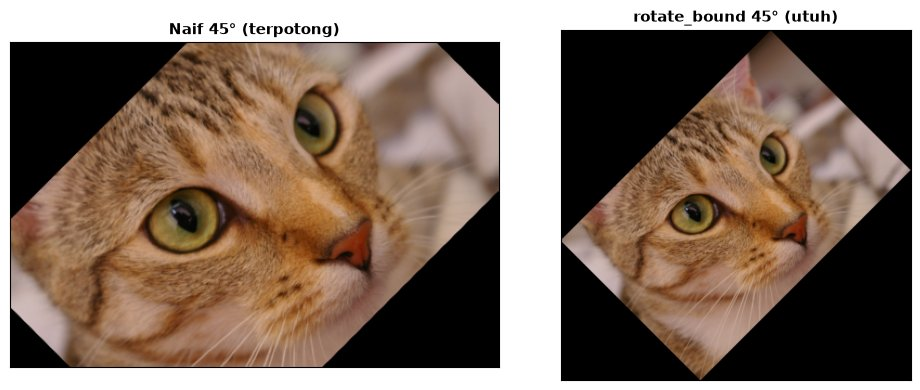

In [32]:
def matriks_bound(w_, h_, sudut):
    # Matriks rotasi + ukuran kanvas baru agar tidak ada bagian yang terpotong
    cx, cy = w_ / 2, h_ / 2
    M = cv2.getRotationMatrix2D((cx, cy), sudut, 1.0)    # langkah 1: rotasi biasa
    cos, sin = abs(M[0, 0]), abs(M[0, 1])                 # M sudah berisi cos & sin
    W_baru = round(w_ * cos + h_ * sin)                   # langkah 2: kanvas baru
    H_baru = round(w_ * sin + h_ * cos)
    M[0, 2] += W_baru / 2 - cx                            # langkah 3: pusat lama -> pusat baru
    M[1, 2] += H_baru / 2 - cy
    return M, (W_baru, H_baru)


def rotate_bound(img, sudut):
    # Putar citra di pusatnya tanpa memotong sudut (kanvas diperbesar)
    h_, w_ = img.shape[:2]
    M, ukuran = matriks_bound(w_, h_, sudut)
    return cv2.warpAffine(img, M, ukuran)                 # langkah 4: eksekusi


for sd in [0, 30, 45, 60, 90]:
    print(f"rotate_bound(kucing, {sd:2d}).shape = {rotate_bound(kucing, sd).shape}")
jajar([(naif, "Naif 45° (terpotong)"), (rotate_bound(kucing, 45), "rotate_bound 45° (utuh)")], ukuran=5)

### 🧩 Challenge 7 — Hitung Kanvas untuk Foto Kopi *(4 menit)*
Foto `kopi` akan diputar **60°**. Hitung ukuran kanvas baru `W_baru` dan `H_baru` (bilangan bulat). Boleh dengan kalkulator atau NumPy.

In [33]:
# 🧩 CHALLENGE 7 — kanvas baru untuk kopi diputar 60°
hk, wk = kopi.shape[:2]
print("kopi: w =", wk, ", h =", hk)

W_baru = None   # TODO: lebar kanvas baru (int)
H_baru = None   # TODO: tinggi kanvas baru (int)

cek_c7(kopi, 60, W_baru, H_baru)

kopi: w = 600 , h = 400
⏳ Masih ada TODO yang bernilai None. Isi dulu, lalu jalankan sel ini lagi.


⏸️ **Kembali ke slide** — pembahasan Challenge 7, lalu anotasi visual.

---
## 9. Anotasi Visual

### 9.1 Fungsi Gambar OpenCV
Semua fungsi menerima titik `(x, y)` **bilangan bulat**, warna **BGR**, dan `thickness` (`-1` = diisi penuh). `cv2.LINE_AA` membuat tepi halus.

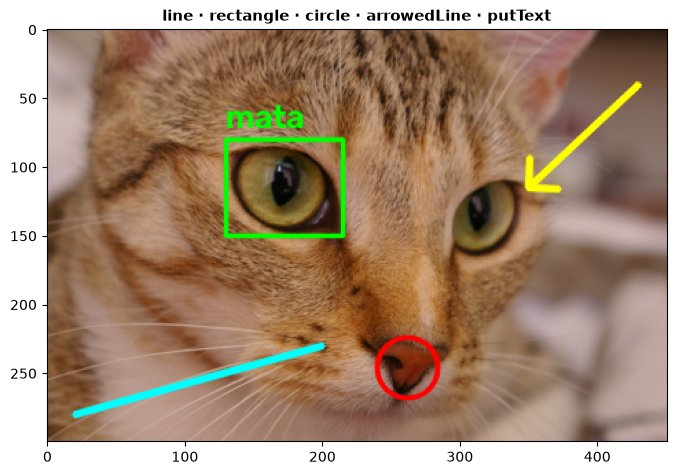

In [34]:
kanvas = kucing.copy()                                                     # SELALU gambar di salinan
cv2.line(kanvas, (20, 280), (200, 230), (255, 255, 0), 3, cv2.LINE_AA)      # titik awal, titik akhir
cv2.rectangle(kanvas, (130, 80), (215, 150), (0, 255, 0), 2, cv2.LINE_AA)   # kiri-atas, kanan-bawah
cv2.circle(kanvas, (262, 246), 22, (0, 0, 255), 2, cv2.LINE_AA)             # pusat, jari-jari
cv2.arrowedLine(kanvas, (430, 40), (350, 115), (0, 255, 255), 3, cv2.LINE_AA, tipLength=0.2)
cv2.putText(kanvas, "mata", (130, 72), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2, cv2.LINE_AA)
#                    teks   titik kiri-BAWAH teks   font                skala  warna   tebal

fig, ax = plt.subplots(figsize=(8, 5.4))
tampil(ax, kanvas, "line · rectangle · circle · arrowedLine · putText", sumbu=True)
plt.show()

### 9.2 Jebakan: Fungsi Gambar Mengubah Citra Asli (*in-place*)

In [35]:
target = kucing.copy()
cv2.rectangle(target, (10, 10), (100, 100), (0, 0, 255), -1)    # tanpa '=', target tetap berubah!
print("target masih sama dengan kucing?", np.array_equal(target, kucing))

try:
    cv2.circle(kucing.copy(), (100.5, 50.2), 10, (0, 0, 255), 2)  # koordinat float
except Exception as err:
    print("Koordinat float ->", type(err).__name__, "| gunakan int(round(...))")

target masih sama dengan kucing? False


Koordinat float -> error | gunakan int(round(...))


### 9.3 Tiga Format Bounding Box
| Format | Isi | Dipakai oleh |
|---|---|---|
| `xywh` | `(x, y, w, h)` kiri-atas + ukuran | OpenCV, COCO |
| `xyxy` | `(x1, y1, x2, y2)` dua sudut | Pascal VOC, `cv2.rectangle` |
| YOLO | `(cx, cy, w, h)` dibagi ukuran citra (0–1) | YOLO |

In [36]:
def xywh_ke_xyxy(box):
    x, y, bw, bh = box
    return (x, y, x + bw, y + bh)


def xyxy_ke_xywh(box):
    x1, y1, x2, y2 = box
    return (x1, y1, x2 - x1, y2 - y1)


def xywh_ke_yolo(box, w_img, h_img):
    x, y, bw, bh = box
    return ((x + bw / 2) / w_img, (y + bh / 2) / h_img, bw / w_img, bh / h_img)


mata_kiri = (130, 80, 85, 70)             # (x, y, w, h)
print("xywh :", mata_kiri)
print("xyxy :", xywh_ke_xyxy(mata_kiri))
print("YOLO :", tuple(round(v, 4) for v in xywh_ke_yolo(mata_kiri, w, h)))
print("balik:", xyxy_ke_xywh(xywh_ke_xyxy(mata_kiri)))

xywh : (130, 80, 85, 70)
xyxy : (130, 80, 215, 150)
YOLO : (0.3825, 0.3833, 0.1885, 0.2333)
balik: (130, 80, 85, 70)


### 9.4 Label yang Selalu Terbaca
`putText` polos sering tenggelam di latar yang ramai. `cv2.getTextSize` memberi ukuran teks sehingga kita bisa menggambar **latar berwarna** di belakangnya. Jika kotak terlalu dekat dengan tepi atas, label dipindah ke dalam kotak.

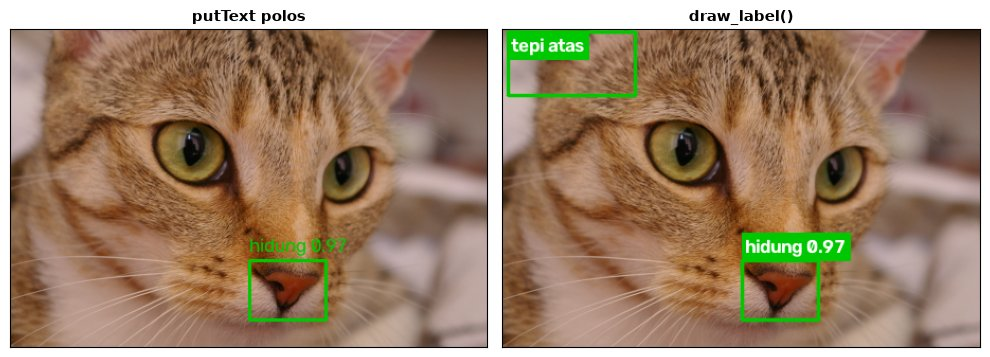

In [37]:
def draw_label(img, box, teks, warna=(0, 200, 0)):
    # Gambar kotak (x, y, w, h) + label teks berlatar warna agar selalu terbaca
    x, y, bw, bh = [int(round(v)) for v in box]
    cv2.rectangle(img, (x, y), (x + bw, y + bh), warna, 2, cv2.LINE_AA)
    font, skala, tebal = cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2
    (tw, th), base = cv2.getTextSize(teks, font, skala, tebal)
    y0 = y - th - base - 6            # tepi atas latar label
    if y0 < 0:                        # tidak muat di atas -> taruh di dalam kotak
        y0 = y
    cv2.rectangle(img, (x, y0), (x + tw + 6, y0 + th + base + 6), warna, -1)
    cv2.putText(img, teks, (x + 3, y0 + th + 3), font, skala, (255, 255, 255), tebal, cv2.LINE_AA)
    return img


polos = kucing.copy()
cv2.rectangle(polos, (226, 218), (298, 274), (0, 200, 0), 2)
cv2.putText(polos, "hidung 0.97", (226, 210), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 200, 0), 1)

rapi = draw_label(kucing.copy(), (226, 218, 72, 56), "hidung 0.97")
draw_label(rapi, (5, 2, 120, 60), "tepi atas")
jajar([(polos, "putText polos"), (rapi, "draw_label()")], ukuran=5)

### 🧩 Challenge 8 — Kotak di Hidung Kucing *(3 menit)*
Kotak hidung diberikan dalam format `xywh`. Tentukan dua titik sudut yang diminta `cv2.rectangle`.

In [38]:
# 🧩 CHALLENGE 8 — kotak hijau di hidung kucing
hidung = (226, 218, 72, 56)          # format (x, y, w, h)
x, y, bw, bh = hidung

pt1 = None   # TODO: sudut kiri-atas
pt2 = None   # TODO: sudut kanan-bawah

hasil = kucing.copy()
if pt1 is not None and pt2 is not None:
    cv2.rectangle(hasil, pt1, pt2, (0, 255, 0), 3)

cek_c8(hidung, pt1, pt2, hasil)

⏳ Masih ada TODO yang bernilai None. Isi dulu, lalu jalankan sel ini lagi.


⏸️ **Kembali ke slide** — pembahasan Challenge 8, lalu integrasi: kotak yang ikut bertransformasi.

---
## 10. Integrasi: Kotak Harus Ikut Bertransformasi

Jika citra diputar/dibalik, koordinat anotasi lama **tidak lagi menunjuk objek yang sama**. Solusinya: transformasikan **4 sudut kotak** dengan matriks `M` yang sama, lalu cari kotak pembungkus barunya. `cv2.transform` mengalikan sekumpulan titik dengan `M`.

### 10.1 Setelah Rotasi

Sudut-sudut baru:
 [[152.8 229.6]
 [226.4 187.1]
 [261.4 247.8]
 [187.8 290.2]]
Kotak lama: (130, 80, 85, 70) | kotak baru (xywh): (153, 187, 109, 103)


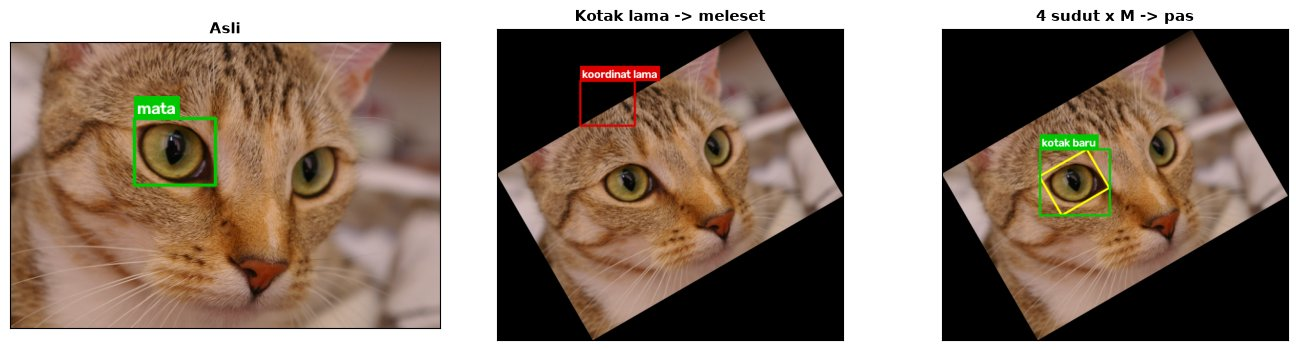

In [39]:
def putar_box(box, M):
    # Transformasikan 4 sudut kotak (x, y, w, h) dengan M, lalu cari kotak pembungkus baru
    x, y, bw, bh = box
    sudut4 = np.float32([[x, y], [x + bw, y], [x + bw, y + bh], [x, y + bh]])
    baru = cv2.transform(sudut4[None], M)[0]      # (4, 2): sudut-sudut di posisi baru
    x1, y1 = baru.min(axis=0)
    x2, y2 = baru.max(axis=0)
    return (x1, y1, x2 - x1, y2 - y1), baru


M_b, ukuran = matriks_bound(w, h, 30)
putar = cv2.warpAffine(kucing, M_b, ukuran)
box_baru, sudut4 = putar_box(mata_kiri, M_b)

salah = draw_label(putar.copy(), mata_kiri, "koordinat lama", (0, 0, 220))
benar = putar.copy()
cv2.polylines(benar, [sudut4.astype(np.int32)], True, (0, 255, 255), 2, cv2.LINE_AA)
draw_label(benar, box_baru, "kotak baru")

print("Sudut-sudut baru:\n", np.round(sudut4, 1))
print("Kotak lama:", mata_kiri, "| kotak baru (xywh):", tuple(int(round(v)) for v in box_baru))
jajar([(draw_label(kucing.copy(), mata_kiri, "mata"), "Asli"), (salah, "Kotak lama -> meleset"),
       (benar, "4 sudut x M -> pas")], ukuran=4.5)

### 10.2 Setelah Flip Horizontal
Flip tidak perlu matriks: cukup pikirkan ke mana tepi-tepi kotak berpindah.

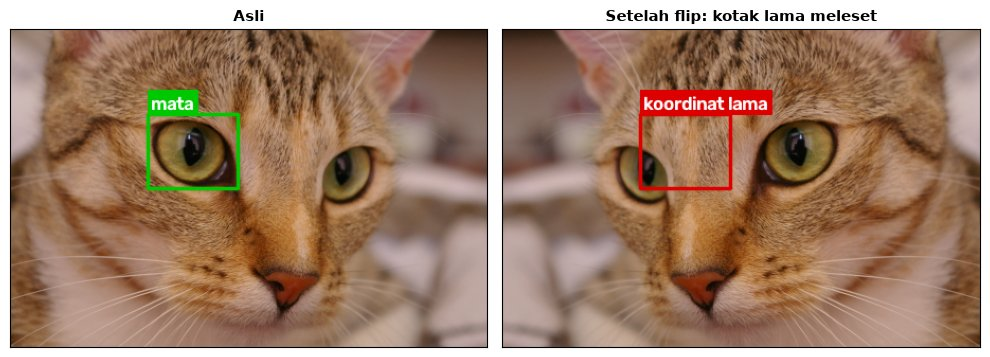

In [40]:
cermin = cv2.flip(kucing, 1)
draw_label(cermin, mata_kiri, "koordinat lama", (0, 0, 220))
jajar([(draw_label(kucing.copy(), mata_kiri, "mata"), "Asli"), (cermin, "Setelah flip: kotak lama meleset")], ukuran=5)

### 🧩 Challenge 9 — Kotak Setelah Flip *(3 menit)*
Setelah `cv2.flip(kucing, 1)`, nilai `y`, `bw`, dan `bh` kotak tidak berubah. Berapa **`x` kiri-atas** yang baru?

In [41]:
# 🧩 CHALLENGE 9 — x baru kotak mata kiri setelah flip horizontal
x, y, bw, bh = mata_kiri
w = kucing.shape[1]

x_baru = None   # TODO: rumus dengan w, x, bw

cek_c9(kucing, mata_kiri, x_baru)

⏳ Masih ada TODO yang bernilai None. Isi dulu, lalu jalankan sel ini lagi.


⏸️ **Kembali ke slide** — pembahasan Challenge 9.

Versi fungsi yang bisa dipakai ulang (misal untuk *data augmentation* pada dataset deteksi objek):

In [42]:
def flip_box_h(box, w_img):
    # Kotak (x, y, w, h) setelah citra dibalik kiri-kanan
    x, y, bw, bh = box
    return (w_img - x - bw, y, bw, bh)


print("mata_kiri          :", mata_kiri)
print("setelah flip       :", flip_box_h(mata_kiri, w))
print("flip dua kali = asli?", flip_box_h(flip_box_h(mata_kiri, w), w) == mata_kiri)

mata_kiri          : (130, 80, 85, 70)
setelah flip       : (236, 80, 85, 70)
flip dua kali = asli? True


---
## 11. Bonus: Meluruskan Foto Dokumen Miring (Perspektif)

Affine selalu menjaga **garis sejajar tetap sejajar**. Pada foto dokumen yang diambil miring, tepi kertas yang aslinya sejajar tampak **menyempit** ke satu arah, sehingga affine tidak cukup. Transformasi **perspektif** (matriks 3×3, *homografi*) memakai **4 pasang titik**: `cv2.getPerspectiveTransform` + `cv2.warpPerspective`.

### 11.1 Simulasi Foto Miring

Matriks perspektif P (3x3):
 [[ 8.550e-01 -2.721e-01  2.500e+02]
 [ 1.406e-01  4.763e-01  6.000e+01]
 [ 1.000e-04 -6.000e-04  1.000e+00]]


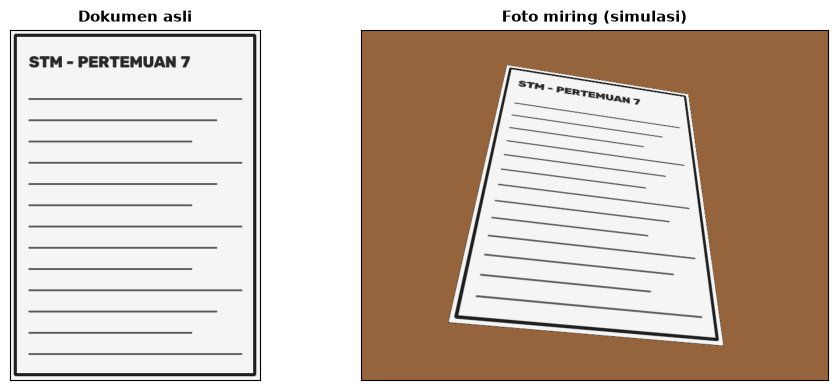

In [43]:
# 1) Dokumen sintetis: kertas putih bergaris + judul
dok = np.full((560, 400, 3), 245, np.uint8)
cv2.putText(dok, "STM - PERTEMUAN 7", (30, 60), cv2.FONT_HERSHEY_DUPLEX, 0.9, (40, 40, 40), 2, cv2.LINE_AA)
for i, yy in enumerate(range(110, 520, 34)):
    cv2.line(dok, (30, yy), (370 - (i % 3) * 40, yy), (90, 90, 90), 2)
cv2.rectangle(dok, (8, 8), (391, 551), (30, 30, 30), 3)

# 2) "Foto miring": tempel dokumen di atas meja dengan perspektif
meja = np.zeros((600, 800, 3), np.uint8)
meja[:] = (60, 100, 150)                                                   # cokelat (BGR)
sudut_dok = np.float32([[0, 0], [399, 0], [399, 559], [0, 559]])           # kiri-atas, kanan-atas, kanan-bawah, kiri-bawah
sudut_foto = np.float32([[250, 60], [560, 110], [620, 540], [150, 500]])
P = cv2.getPerspectiveTransform(sudut_dok, sudut_foto)
lembar = cv2.warpPerspective(dok, P, (800, 600))
area = cv2.warpPerspective(np.full(dok.shape[:2], 255, np.uint8), P, (800, 600))
foto = np.where(area[..., None] > 0, lembar, meja)

print("Matriks perspektif P (3x3):\n", np.round(P, 4))
jajar([(dok, "Dokumen asli"), (foto, "Foto miring (simulasi)")], ukuran=5)

### 11.2 Affine (3 Titik) vs Perspektif (4 Titik)

Selisih rata-rata hasil perspektif vs dokumen asli: 4.62 (skala 0-255)


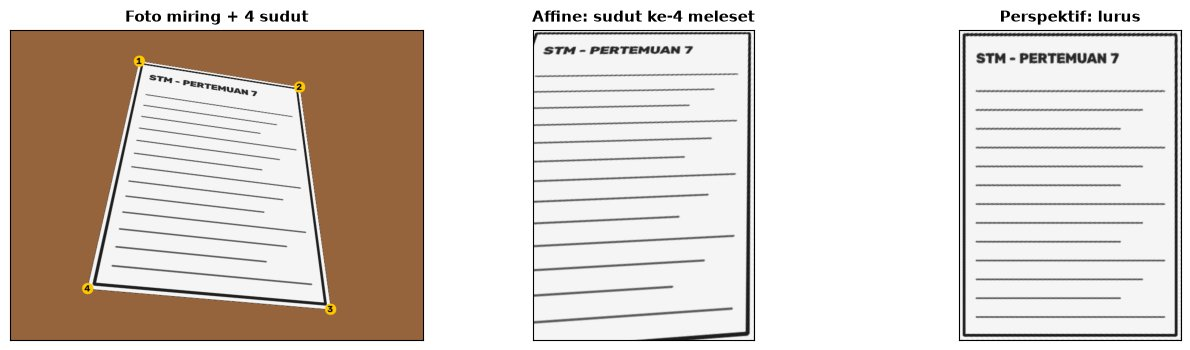

In [44]:
A = cv2.getAffineTransform(sudut_foto[:3], sudut_dok[:3])            # hanya 3 titik
lurus_affine = cv2.warpAffine(foto, A, (400, 560))

P_balik = cv2.getPerspectiveTransform(sudut_foto, sudut_dok)          # 4 titik
lurus = cv2.warpPerspective(foto, P_balik, (400, 560))

tanda = foto.copy()
for i, (px, py) in enumerate(sudut_foto.astype(int)):
    cv2.circle(tanda, (px, py), 11, (0, 200, 255), -1)
    cv2.putText(tanda, str(i + 1), (px - 6, py + 6), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)

print("Selisih rata-rata hasil perspektif vs dokumen asli:", round(float(cv2.absdiff(lurus, dok).mean()), 2), "(skala 0-255)")
jajar([(tanda, "Foto miring + 4 sudut"), (lurus_affine, "Affine: sudut ke-4 meleset"), (lurus, "Perspektif: lurus")], ukuran=4.5)

### 11.3 Coba dengan Foto Anda Sendiri (Tugas Persiapan)
1. Simpan foto dokumen/papan tulis miring Anda ke folder `image/`.
2. Tampilkan foto dengan `plt.imshow` (atau jalankan sel ini sekali), lalu baca koordinat 4 sudut dari sumbu x/y.
3. Isi `FOTO_SAYA` dan `SUDUT_SAYA` dengan urutan: **kiri-atas, kanan-atas, kanan-bawah, kiri-bawah**.

In [45]:
FOTO_SAYA = None     # contoh: "image/foto_saya.jpg"
SUDUT_SAYA = None    # contoh: [(120, 80), (900, 140), (950, 1200), (60, 1150)]

if FOTO_SAYA is None:
    print("Lewati: isi FOTO_SAYA (dan SUDUT_SAYA) untuk mencoba foto Anda sendiri.")
else:
    img_saya = cv2.imread(FOTO_SAYA)
    if img_saya is None:
        raise FileNotFoundError(FOTO_SAYA)
    if SUDUT_SAYA is None:
        fig, ax = plt.subplots(figsize=(8, 6))
        tampil(ax, img_saya, "Baca koordinat 4 sudut dari sumbu", sumbu=True)
        plt.show()
    else:
        src = np.float32(SUDUT_SAYA)
        lebar = int(max(np.linalg.norm(src[1] - src[0]), np.linalg.norm(src[2] - src[3])))
        tinggi = int(max(np.linalg.norm(src[3] - src[0]), np.linalg.norm(src[2] - src[1])))
        dst = np.float32([[0, 0], [lebar - 1, 0], [lebar - 1, tinggi - 1], [0, tinggi - 1]])
        hasil_saya = cv2.warpPerspective(img_saya, cv2.getPerspectiveTransform(src, dst), (lebar, tinggi))
        jajar([(img_saya, "Foto Anda"), (hasil_saya, f"Diluruskan {lebar}x{tinggi}")], ukuran=5)

Lewati: isi FOTO_SAYA (dan SUDUT_SAYA) untuk mencoba foto Anda sendiri.


---
## 12. Rangkuman & Kebiasaan Baik

### 📌 Ringkasan Konsep Inti Modul 08:
1. **Transformasi geometris** memindahkan **alamat** piksel $(x, y) \to (x', y')$, bukan mengubah nilainya. NumPy memakai `img[y, x]` dan `shape = (H, W, C)`; OpenCV memakai titik `(x, y)` dan ukuran `(W, H)`.
2. **Translasi & flipping** bisa dilakukan dengan slicing NumPy. `cv2.flip(img, 1)` = kiri-kanan, `0` = atas-bawah, `-1` = keduanya (= rotasi 180°).
3. OpenCV memakai **inverse mapping**: setiap piksel tujuan "menarik" nilai dari alamat asal yang sering pecahan, lalu **diinterpolasi**.
4. Pilih interpolasi sesuai tujuan: `NEAREST` untuk mask/label & pixel art, `LINEAR` (default) atau `CUBIC` untuk memperbesar, `AREA` untuk **memperkecil** (mencegah aliasing).
5. **Rotasi** di pusat = geser → putar → geser balik, dirangkum oleh `cv2.getRotationMatrix2D`. **Angle positif = berlawanan jarum jam.**
6. **Matriks affine 2×3** menyatukan translasi, scaling, flipping, rotasi, dan shear; ditentukan oleh 3 pasang titik.
7. **Kanvas baru** rotasi: $W' = w|\cos\theta| + h|\sin\theta|$, $H' = w|\sin\theta| + h|\cos\theta|$, lalu geser pusat lama ke pusat baru.
8. **Anotasi**: gambar di **salinan**, koordinat **int**, warna **BGR**, label berlatar agar terbaca; kotak harus **ikut ditransformasi** bersama citra.

### 🧭 Lembar Contekan
| Tujuan | Kode |
|---|---|
| Ukuran citra | `h, w = img.shape[:2]` |
| Ubah ukuran | `cv2.resize(img, (W, H), interpolation=cv2.INTER_AREA)` |
| Cermin | `cv2.flip(img, 1)` |
| Putar di pusat | `M = cv2.getRotationMatrix2D((w/2, h/2), sudut, 1.0)` → `cv2.warpAffine(img, M, (w, h))` |
| Translasi | `M = np.float32([[1, 0, tx], [0, 1, ty]])` |
| Titik × matriks | `cv2.transform(titik[None], M)[0]` |
| Kotak | `cv2.rectangle(img, (x, y), (x + bw, y + bh), (0, 255, 0), 2)` |
| Teks | `cv2.putText(img, teks, (x, y), cv2.FONT_HERSHEY_SIMPLEX, 0.6, warna, 2, cv2.LINE_AA)` |
| Perspektif | `cv2.warpPerspective(img, cv2.getPerspectiveTransform(src4, dst4), (W, H))` |

> 🔜 **Pertemuan berikutnya:** Filtering spasial (konvolusi), Gaussian blur & sharpening, serta deteksi tepi & kontur.